# Análise de Hipóteses de loja Online 
Analise junto com o departamento de marketing sobre as hipóteses compiladas que podem ajudar a aumentar receitas para a loja. Utilizando métodos de teste A/B, utilizando frameworks ICE, RICE e gráficos para a análise. 

<b>CADA DATA FRAME POSSUI AS SEGUINTES COLUNAS:</b>


 * Hypotheses: '/datasets/hypotheses_us.csv' 

<b>Hypotheses</b> — breves descrições das hipóteses

<b>Reach</b> — alcance do usuário, em uma escala de um a dez

<b>Impact</b> — impacto nos usuários, em uma escala de um a dez

<b>Confidence</b> — confiança na hipótese, em uma escala de um a dez

<b>Effort</b> — os recursos necessários para testar uma hipótese, em uma escala de um a dez. 

* Orders : '/datasets/orders_us.csv' 

<b>transactionId</b> — identificador do pedido

<b>visitorId</b> — identificador do usuário que fez o pedido

<b>date</b> — do pedido

<b>revenue</b> — do pedido

<b>group</b> — o grupo de teste A/B ao qual o usuário pertence

*Visits: '/datasets/visits_us.csv'

<b>date</b> — data

<b>group</b> — grupo de teste A/B

</b>visits</b> — o número de visitas na data especificada para o grupo de teste A/B especificado.

Primeiro irei fazer o pré-processamento, limpeza e ánalise dos dados e depois passarei a ánalisar as hipóteses. Começando com os frameworks ICE e RICE e, na parte 2, o teste A/B.




In [1]:
# IMPORTANDO AS BIBLIOTECAS E OS DATA FRAMES 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

hypotheses = pd.read_csv('/datasets/hypotheses_us.csv', sep= ';')
orders = pd.read_csv('/datasets/orders_us.csv')
visits = pd.read_csv('/datasets/visits_us.csv')

print(hypotheses.head(5))
print()
print(orders.head(5))
print()
print(visits.head(5))



                                          Hypothesis  Reach  Impact  \
0  Add two new channels for attracting traffic. T...      3      10   
1  Launch your own delivery service. This will sh...      2       5   
2  Add product recommendation blocks to the store...      8       3   
3  Change the category structure. This will incre...      8       3   
4  Change the background color on the main page. ...      3       1   

   Confidence  Effort  
0           8       6  
1           4      10  
2           7       3  
3           3       8  
4           1       1  

   transactionId   visitorId        date  revenue group
0     3667963787  3312258926  2019-08-15     30.4     B
1     2804400009  3642806036  2019-08-15     15.2     B
2     2961555356  4069496402  2019-08-15     10.2     A
3     3797467345  1196621759  2019-08-15    155.1     B
4     2282983706  2322279887  2019-08-15     40.5     B

         date group  visits
0  2019-08-01     A     719
1  2019-08-02     A     619
2  2019

In [2]:
#analisando as informações das tabelas e colunas 
print('Tabela Hypotheses')
print(hypotheses.info())
print()
print('Tabela orders')
print(orders.info())
print()
print('Tabela visits')
print(visits.info())



Tabela Hypotheses
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Hypothesis  9 non-null      object
 1   Reach       9 non-null      int64 
 2   Impact      9 non-null      int64 
 3   Confidence  9 non-null      int64 
 4   Effort      9 non-null      int64 
dtypes: int64(4), object(1)
memory usage: 488.0+ bytes
None

Tabela orders
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   transactionId  1197 non-null   int64  
 1   visitorId      1197 non-null   int64  
 2   date           1197 non-null   object 
 3   revenue        1197 non-null   float64
 4   group          1197 non-null   object 
dtypes: float64(1), int64(2), object(2)
memory usage: 46.9+ KB
None

Tabela visits
<class 'pandas.core.frame.Data

In [3]:
#ajustando as colunas para date time e checando os numeros duplicados dos dataframes
orders['date'] = pd.to_datetime(orders['date'])
visits['date'] = pd.to_datetime(visits['date'])
#duplicados
print(orders.duplicated().sum())
print(visits.duplicated().sum())
print(orders.isna().sum())
print(visits.isna().sum())

#certificando que os visitantes não estão no mesmo grupo 
orders.groupby('visitorId')['group'].nunique().value_counts()


0
0
transactionId    0
visitorId        0
date             0
revenue          0
group            0
dtype: int64
date      0
group     0
visits    0
dtype: int64


1    973
2     58
Name: group, dtype: int64

In [4]:
# quantidade de visitas 
groups_per_visitor = orders.groupby('visitorId')['group'].nunique()

visitors_both_groups = groups_per_visitor[
    groups_per_visitor > 1
]
percentage = len(visitors_both_groups) / orders['visitorId'].nunique() * 100

print(f'{percentage:.2f}%')

5.63%


# OBSERVAÇÃO #
Foi encontrado alguns visitantes que participavam dos dois grupos. Vou analisar os valores dos pedidos dos visitantes que estão nos dois grupos, para observar se pode ocorrer possivel outliers e qual a porcentagem na receita desses visitantes para observar a possivel exclusão desses participantes

In [5]:
# separandos os pedidos dos visitantes que participam dos dois grupo 
orders_both_groups = orders[
    orders['visitorId'].isin(visitors_both_groups.index)
]
#analisando os valores 
print(orders_both_groups.groupby('group')['revenue'].agg(
    ['count', 'sum', 'mean', 'median']
))


#porcentagem na receitas desses visitantes 
percentage_revenue = (
    orders_both_groups['revenue'].sum()
    / orders['revenue'].sum()
    * 100
)

print(f'{percentage_revenue:.2f}%')

       count      sum        mean  median
group                                    
A         89  11342.9  127.448315    45.9
B         92  13189.4  143.363043    68.0
15.59%


In [6]:
#frequencia de pedidos por visitante duplicados 
orders_both_groups.groupby('visitorId')['transactionId'].nunique().describe()

count    58.000000
mean      3.120690
std       2.094919
min       2.000000
25%       2.000000
50%       2.000000
75%       3.000000
max      11.000000
Name: transactionId, dtype: float64

In [7]:
#limpando os dados 
#criando um data novo sem os visitantes duplicados
orders_clean = orders[
    ~orders['visitorId'].isin(visitors_both_groups.index)
].copy()
#agrupando os visitantes unicos
orders_clean.groupby('visitorId')['group'].nunique().value_counts()

1    973
Name: group, dtype: int64

In [8]:
#frequencia dos outros visitantes dos grupo a-b
orders_clean.groupby('visitorId')['transactionId'].nunique().describe()

count    973.000000
mean       1.044193
std        0.238090
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        3.000000
Name: transactionId, dtype: float64


# RESULTADO DA LIMPEZA DE DADOS 

Durante o pré-processamento, converti as colunas de data para o formato `datetime` e investiguei possíveis inconsistências nos dados.

Identifiquei que **58 visitantes (5,63% dos compradores únicos)** estavam presentes nos grupos A e B do teste, sendo responsáveis por **15,59% da receita total**.

Ao analisar a frequência de compras, observei que esses visitantes realizaram, em média, **3,12 pedidos por pessoa**, enquanto os visitantes presentes em apenas um grupo realizaram, em média, **1,04 pedido**.
O principal motivo para excluí-los pois podem contaminar ambos os grupos e quebrar a independência que o teste pressupõe.

Diante dessa inconsistência, removi os pedidos desses 58 visitantes da base utilizada na análise principal, buscando evitar a contaminação dos grupos e possíveis distorções nos resultados do teste A/B.

**Limitação:** a tabela `visits` contém dados agregados por data e grupo, impossibilitando a exclusão individual das visitas desses participantes. Essa limitação deverá ser considerada na interpretação dos resultados.

# PRIORIZANDO AS HIPÓTESES E APLICANDO OS FRAMEWORKS 

In [9]:
#APLICANDO O FRAMEWORK ICE E CLASSIFICANDO EM ORDEM DECRESCENTE
ICE = hypotheses['Impact'] * hypotheses['Confidence'] / hypotheses['Effort']
hypotheses['ICE'] = ICE

print(hypotheses.sort_values(by= 'ICE', ascending = False))






                                          Hypothesis  Reach  Impact  \
8  Launch a promotion that gives users discounts ...      1       9   
0  Add two new channels for attracting traffic. T...      3      10   
7  Add a subscription form to all the main pages....     10       7   
6  Show banners with current offers and sales on ...      5       3   
2  Add product recommendation blocks to the store...      8       3   
1  Launch your own delivery service. This will sh...      2       5   
5  Add a customer review page. This will increase...      3       2   
3  Change the category structure. This will incre...      8       3   
4  Change the background color on the main page. ...      3       1   

   Confidence  Effort        ICE  
8           9       5  16.200000  
0           8       6  13.333333  
7           8       5  11.200000  
6           8       3   8.000000  
2           7       3   7.000000  
1           4      10   2.000000  
5           2       3   1.333333  
3        

In [10]:
#aplicando o framework rice e aplicando em ordem descrecente 

RICE =  hypotheses['Reach'] * hypotheses['Impact'] * hypotheses['Confidence'] / hypotheses['Effort']

hypotheses['RICE'] = RICE 

print(hypotheses.sort_values( by= 'RICE', ascending = False))

                                          Hypothesis  Reach  Impact  \
7  Add a subscription form to all the main pages....     10       7   
2  Add product recommendation blocks to the store...      8       3   
0  Add two new channels for attracting traffic. T...      3      10   
6  Show banners with current offers and sales on ...      5       3   
8  Launch a promotion that gives users discounts ...      1       9   
3  Change the category structure. This will incre...      8       3   
1  Launch your own delivery service. This will sh...      2       5   
5  Add a customer review page. This will increase...      3       2   
4  Change the background color on the main page. ...      3       1   

   Confidence  Effort        ICE   RICE  
7           8       5  11.200000  112.0  
2           7       3   7.000000   56.0  
0           8       6  13.333333   40.0  
6           8       3   8.000000   40.0  
8           9       5  16.200000   16.2  
3           3       8   1.125000    9

In [11]:
hypotheses['ICE_rank'] = (
    hypotheses['ICE'].rank(ascending=False, method='min')
)

hypotheses['RICE_rank'] = (
    hypotheses['RICE'].rank(ascending=False, method='min')
)

display(
    hypotheses[
        ['Hypothesis', 'ICE_rank', 'RICE_rank']
    ].sort_values(by='ICE_rank')
)


,Hypothesis,ICE_rank,RICE_rank
8,Launch a promotion that gives users discounts ...,1.0,5.0
0,Add two new channels for attracting traffic. T...,2.0,3.0
7,Add a subscription form to all the main pages....,3.0,1.0
6,Show banners with current offers and sales on ...,4.0,3.0
2,Add product recommendation blocks to the store...,5.0,2.0
1,Launch your own delivery service. This will sh...,6.0,7.0
5,Add a customer review page. This will increase...,7.0,7.0
3,Change the category structure. This will incre...,8.0,6.0
4,Change the background color on the main page. ...,9.0,9.0


# CONCLUSÃO DAS PRIORIZAÇÃO DAS HIPÓTESES

### Conclusão — Comparação dos frameworks ICE e RICE

Ao comparar os frameworks ICE e RICE, observei mudanças importantes na ordem de priorização das hipóteses.

No framework ICE, a hipótese de **promoção de desconto** apresentou a maior pontuação (16,20), seguida pelas hipóteses 0 (13,33) e de **formulário de assinatura** (11,20).

Entretanto, ao aplicar o RICE, a hipótese de **formulário de assinatura** passou da 3ª para a 1ª posição, com 112 pontos, devido ao seu alto alcance (Reach 10).

A hipótese de **blocos de recomendação de produtos** também ganhou prioridade, passando da 5ª para a 2ª posição, com 56 pontos, pois possui um alcance de 8.

Por outro lado, a hipótese de **promoção de desconto**, que ocupava a primeira posição no ICE, caiu para a quinta posição no RICE, devido ao seu alcance reduzido (Reach 1).

Também observei hipóteses que permaneceram na mesma posição, como a **mudança de cor de fundo**, que continuou em último lugar nos dois frameworks.

Essas alterações mostram que o alcance influencia significativamente a classificação das hipóteses. Enquanto o ICE prioriza a relação entre impacto, confiança e esforço, o RICE acrescenta a quantidade estimada de usuários que poderão ser alcançados.

**Portanto, considerando o objetivo de alcançar um maior número de usuários, o RICE pode ser mais adequado para orientar a priorização das hipóteses.**



# Ánalise de teste A/B


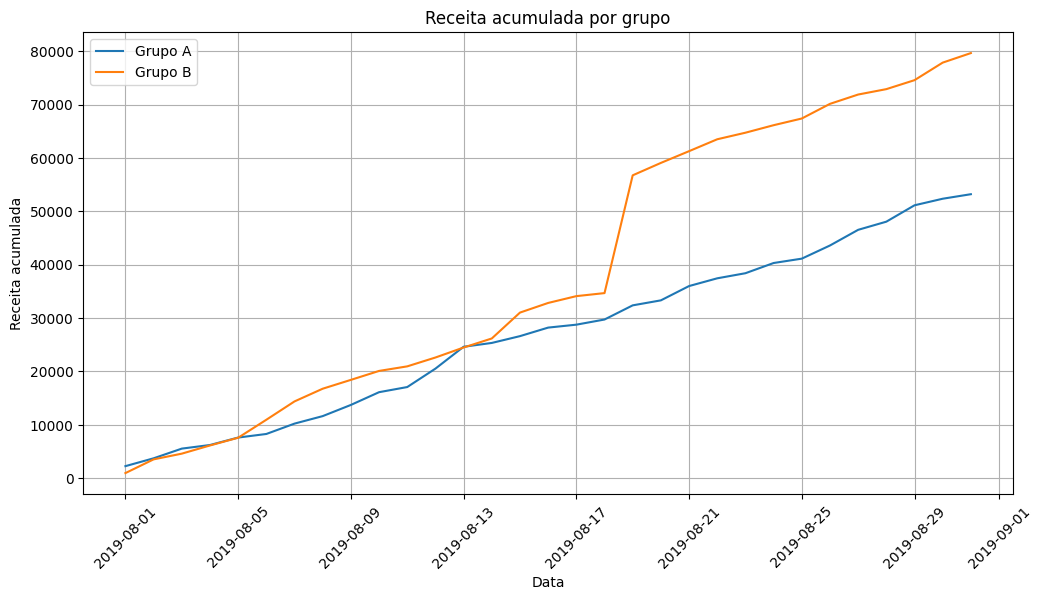

In [12]:
# # Pares únicos de datas e grupos
datesGroups = orders_clean[['date', 'group']].drop_duplicates()

# Pedidos acumulados por data e grupo
ordersAggregated = datesGroups.apply(
    lambda x: orders_clean[
        (orders_clean['date'] <= x['date']) &
        (orders_clean['group'] == x['group'])
    ].agg({
        'date': 'max',
        'group': 'max',
        'transactionId': 'nunique',
        'visitorId': 'nunique',
        'revenue': 'sum'
    }),
    axis=1
).sort_values(by=['date', 'group'])

# Visitas acumuladas por data e grupo
visitorsAggregated = datesGroups.apply(
    lambda x: visits[
        (visits['date'] <= x['date']) &
        (visits['group'] == x['group'])
    ].agg({
        'date': 'max',
        'group': 'max',
        'visits': 'sum'
    }),
    axis=1
).sort_values(by=['date', 'group'])

# Unindo os dados
cumulativeData = ordersAggregated.merge(
    visitorsAggregated,
    on=['date', 'group']
)

cumulativeData.columns = [
    'date', 'group', 'orders', 'buyers', 'revenue', 'visitors'
]

# Receita acumulada dos grupos
cumulativeRevenueA = cumulativeData[
    cumulativeData['group'] == 'A'
]

cumulativeRevenueB = cumulativeData[
    cumulativeData['group'] == 'B'
]

# Gráfico
plt.figure(figsize=(12, 6))

plt.plot(
    cumulativeRevenueA['date'],
    cumulativeRevenueA['revenue'],
    label='Grupo A'
)

plt.plot(
    cumulativeRevenueB['date'],
    cumulativeRevenueB['revenue'],
    label='Grupo B'
)

plt.title('Receita acumulada por grupo')
plt.xlabel('Data')
plt.ylabel('Receita acumulada')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

In [13]:


#Selecionando os pedidos do grupo B
orders_B = orders_clean[orders_clean['group'] == 'B'].copy()

# Calculando a receita diária e acumulada
revenue_B = (
    orders_B.groupby('date')['revenue']
    .sum()
    .sort_index()
    .reset_index(name='daily_revenue')
)

revenue_B['cumulative_revenue'] = (
    revenue_B['daily_revenue'].cumsum()
)

#Visualizando a receita próxima ao salto
print('Receita do grupo B entre 16 e 21 de agosto:')

display(
    revenue_B[
        revenue_B['date'].between('2019-08-16', '2019-08-21')
    ]
)

# Identificando automaticamente o dia com maior aumento
jump_date = revenue_B.loc[
    revenue_B['daily_revenue'].idxmax(), 'date'
]

print(f'Data do maior salto: {jump_date.date()}')

#Selecionando os pedidos dessa data
orders_jump = orders_B[
    orders_B['date'] == jump_date
].sort_values(by='revenue', ascending=False)

print('Pedidos realizados na data do maior salto:')
display(orders_jump)

#Calculando a receita total do dia
daily_revenue = orders_jump['revenue'].sum()

# Calculando a receita dos dois maiores pedidos
top_two_revenue = (
    orders_jump.nlargest(2, 'revenue')['revenue'].sum()
)

# Calculando a participação dos dois maiores pedidos
percentage = (
    top_two_revenue / daily_revenue * 100
)

print(f'Receita total do dia: {daily_revenue:.2f}')
print(f'Receita dos dois maiores pedidos: {top_two_revenue:.2f}')
print(f'Participação dos dois pedidos: {percentage:.2f}%')

# Visualizando os 10 maiores pedidos de todo o grupo B
print('Os 10 maiores pedidos do grupo B:')

display(
    orders_B.sort_values(
        by='revenue',
        ascending=False
    )[
        ['date', 'transactionId', 'visitorId', 'revenue']
    ].head(10)
)

top_order = orders_jump.iloc[0]['revenue']

print(f'Participação na receita do dia: {top_order / daily_revenue * 100:.2f}%')

print(f'Participação na receita total de B: {top_order / orders_B["revenue"].sum() * 100:.2f}%')


Receita do grupo B entre 16 e 21 de agosto:


,date,daily_revenue,cumulative_revenue
15,2019-08-16,1807.0,32840.2
16,2019-08-17,1276.0,34116.2
17,2019-08-18,568.5,34684.7
18,2019-08-19,22064.9,56749.6
19,2019-08-20,2324.6,59074.2
20,2019-08-21,2200.2,61274.4


Data do maior salto: 2019-08-19
Pedidos realizados na data do maior salto:


,transactionId,visitorId,date,revenue,group
425,590470918,1920142716,2019-08-19,19920.4,B
527,1570513684,2837914161,2019-08-19,515.9,B
461,2683113224,154576532,2019-08-19,410.5,B
368,3268879337,2536252163,2019-08-19,310.1,B
463,4170537404,290022471,2019-08-19,255.5,B
423,4161654914,990904712,2019-08-19,175.1,B
523,1739748874,522292794,2019-08-19,80.1,B
367,1033377712,3860669668,2019-08-19,65.4,B
529,90109939,2075769885,2019-08-19,55.2,B
426,19467429,2397843657,2019-08-19,45.5,B


Receita total do dia: 22064.90
Receita dos dois maiores pedidos: 20436.30
Participação dos dois pedidos: 92.62%
Os 10 maiores pedidos do grupo B:


,date,transactionId,visitorId,revenue
425,2019-08-19,590470918,1920142716,19920.4
1196,2019-08-15,3936777065,2108080724,3120.1
744,2019-08-27,3668308183,888512513,1335.6
940,2019-08-08,2420050534,4003628586,905.8
613,2019-08-07,4071177889,3931967268,830.3
1142,2019-08-13,3815014015,2606908679,815.8
755,2019-08-30,1234615529,2279926127,705.3
339,2019-08-25,2216192667,834731816,640.7
78,2019-08-16,773663763,3288820196,630.8
1087,2019-08-12,324171086,3590655705,610.7


Participação na receita do dia: 90.28%
Participação na receita total de B: 25.01%



### Conclusão — Receita acumulada por grupo

Ao analisar o gráfico de receita acumulada, observei que os grupos A e B apresentaram um crescimento relativamente próximo durante a primeira metade do teste.

Entretanto, no dia 19 de agosto, o grupo B apresentou um aumento expressivo na receita acumulada, passando de aproximadamente 35 mil para 57 mil.

Ao investigar os pedidos dessa data, identifiquei que a receita total foi de 22.064,90, sendo que **um único pedido de 19.920,40 representou aproximadamente 90,28% da receita diária e cerca de um quarto da receita total do grupo B**.

Esse pedido excepcional foi o principal responsável pelo salto observado no gráfico. Uma possível explicação seria uma compra em grande quantidade ou até mesmo um erro no registro do valor, sendo necessária uma investigação para confirmar sua origem.

Após esse aumento, o grupo B continuou acumulando receita e manteve sua vantagem até o final do teste, encerrando próximo de 80 mil, enquanto o grupo A terminou próximo de 53 mil.

**Portanto, embora o grupo B tenha apresentado maior receita acumulada, sua vantagem foi fortemente influenciada por um único pedido de valor excepcionalmente alto, não sendo possível concluir apenas pelo gráfico que houve uma melhoria consistente no desempenho do grupo B.**


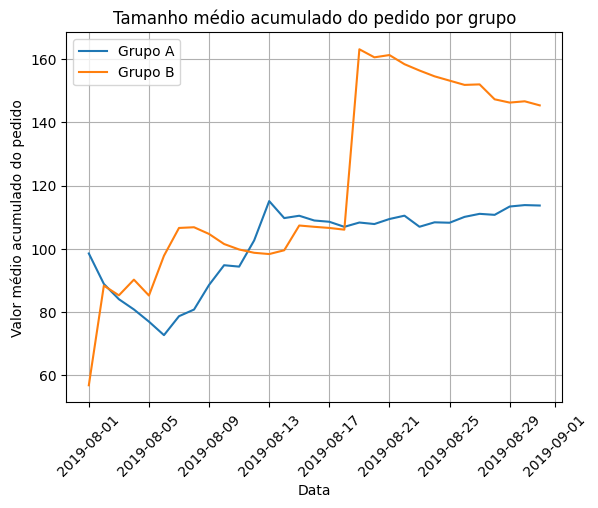

In [14]:
#gráfico do tamanho médio acumulado do pedido por grupo 
# Tamanho médio acumulado do pedido - Grupo A
plt.plot(
    cumulativeRevenueA['date'],
    cumulativeRevenueA['revenue'] / cumulativeRevenueA['orders'],
    label='Grupo A'
)

# Tamanho médio acumulado do pedido - Grupo B
plt.plot(
    cumulativeRevenueB['date'],
    cumulativeRevenueB['revenue'] / cumulativeRevenueB['orders'],
    label='Grupo B'
)

plt.title('Tamanho médio acumulado do pedido por grupo')
plt.xlabel('Data')
plt.ylabel('Valor médio acumulado do pedido')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()


### Conclusão — Tamanho médio acumulado dos pedidos por grupo

Ao analisar o gráfico, observei que o grupo B iniciou o teste com um valor médio acumulado próximo de 57, enquanto o grupo A começou próximo de 98. Durante os primeiros dias, as médias apresentaram oscilações e as curvas se cruzaram diversas vezes, sem uma vantagem constante entre os grupos.

No dia **19 de agosto**, o grupo B apresentou um aumento expressivo na média acumulada, passando de aproximadamente 106 para 163.

Ao investigar esse aumento, identifiquei um único pedido de **19.920,40**, responsável por aproximadamente **90% da receita daquele dia**. Esse valor excepcional influenciou significativamente a média acumulada do grupo B, explicando o salto observado no gráfico.

Após esse período, a média acumulada do grupo B diminuiu gradualmente, embora sua receita continuasse crescendo. Isso sugere que os pedidos posteriores apresentaram, em conjunto, valores médios inferiores à média acumulada anterior.

Ao final do teste, o grupo A encerrou com uma média próxima de 114, enquanto o grupo B terminou próximo de 145.

**Portanto, embora o grupo B tenha apresentado maior valor médio acumulado por pedido, sua vantagem foi fortemente influenciada por uma única compra excepcional. Essa observação será considerada na análise dos valores atípicos e nos testes estatísticos antes de concluir se existe uma diferença consistente entre os grupos.**

### Gráfico do tamanho médio acumulado do pedido comparando o grupo B com o grupo A

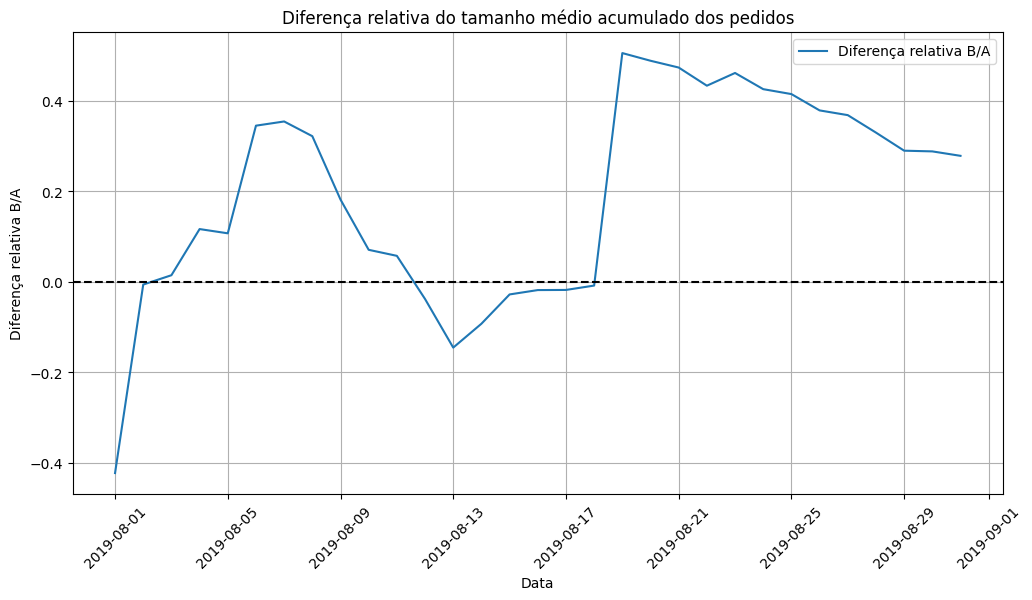

In [15]:

# Agrupando os pedidos por data e grupo
daily_orders = (
    orders_clean.groupby(['date', 'group'])
    .agg(
        revenue=('revenue', 'sum'),
        orders=('transactionId', 'nunique')
    )
    .reset_index()
)

# Criando uma sequência de datas para cada grupo
dates = pd.date_range(
    orders_clean['date'].min(),
    orders_clean['date'].max()
)

date_groups = pd.MultiIndex.from_product(
    [dates, ['A', 'B']],
    names=['date', 'group']
)

daily_orders = (
    daily_orders.set_index(['date', 'group'])
    .reindex(date_groups, fill_value=0)
    .reset_index()
)

# Calculando os valores acumulados
daily_orders['revenue_cumulative'] = (
    daily_orders.groupby('group')['revenue'].cumsum()
)

daily_orders['orders_cumulative'] = (
    daily_orders.groupby('group')['orders'].cumsum()
)

# Separando os grupos
groupA = daily_orders[daily_orders['group'] == 'A']
groupB = daily_orders[daily_orders['group'] == 'B']

# Juntando os grupos pela data
merged = groupA.merge(
    groupB,
    on='date',
    suffixes=['A', 'B']
)

# Calculando a diferença relativa
averageA = (
    merged['revenue_cumulativeA'] /
    merged['orders_cumulativeA']
)

averageB = (
    merged['revenue_cumulativeB'] /
    merged['orders_cumulativeB']
)

relative_difference = (averageB / averageA) - 1

# Construindo o gráfico
plt.figure(figsize=(12, 6))

plt.plot(
    merged['date'],
    relative_difference,
    label='Diferença relativa B/A'
)

plt.axhline(y=0, color='black', linestyle='--')

plt.title('Diferença relativa do tamanho médio acumulado dos pedidos')
plt.xlabel('Data')
plt.ylabel('Diferença relativa B/A')

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

### Conclusão — Diferença relativa do valor médio acumulado dos pedidos (B/A)

Ao analisar o gráfico, observei grandes oscilações na diferença relativa durante os primeiros dias do teste. O grupo B começou aproximadamente 40% abaixo do grupo A, alcançou uma vantagem de 35% entre os dias 6 e 7 de agosto e voltou a apresentar uma diferença negativa de aproximadamente 15% por volta do dia 13, permanecendo levemente abaixo do grupo A até o dia 18.

No dia **19 de agosto**, ocorreu um salto expressivo na diferença relativa, chegando a aproximadamente 50% a favor do grupo B. Ao investigar esse aumento, identifiquei um único pedido excepcional de **19.920,40**, responsável por cerca de **90% da receita daquele dia**, influenciando significativamente a média acumulada do grupo B.

Após esse salto, a diferença relativa diminuiu gradualmente, encerrando o teste próxima de **28% a favor do grupo B**.

**Portanto, embora o grupo B tenha apresentado maior valor médio acumulado por pedido ao final do teste, sua vantagem parece ter sido fortemente impulsionada por um único pedido extremo, e não necessariamente por uma melhoria consistente no valor das compras.**

### TAXA DE CONVERSÃO DE CADA GRUPO E A PROPORÇÃO DE PEDIDOS PARA O NÚMERO DE VISITAS PARA CADA DIA 

,Conversão limpa (%),Conversão original (%),Diferença (p.p.)
group,,,
A,2.498,2.973,0.475
B,2.897,3.383,0.486


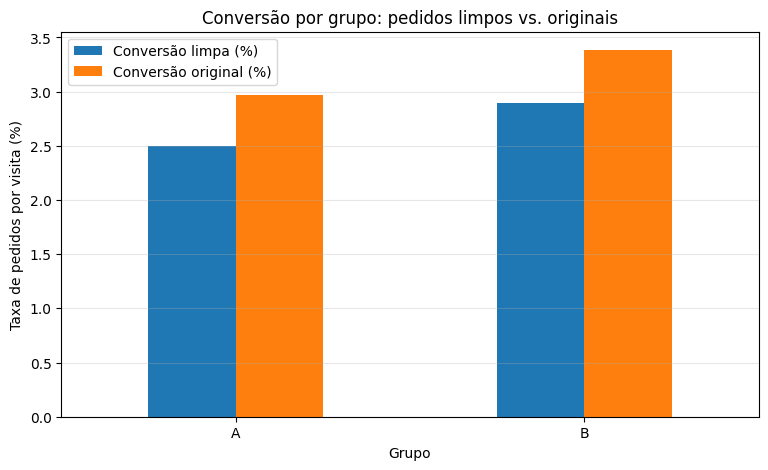

In [16]:
# Função para calcular a conversão diária
def calcular_conversao(df_orders, nome_cenario):

    pedidos = (
        df_orders.groupby(['date', 'group'])['transactionId']
        .nunique()
        .reset_index(name='orders')
    )

    resultado = visits.merge(
        pedidos,
        on=['date', 'group'],
        how='left'
    )

    resultado['orders'] = resultado['orders'].fillna(0)

    resultado['conversion'] = (
        resultado['orders'] / resultado['visits'] * 100
    )

    resultado['cenario'] = nome_cenario

    return resultado


# Conversão usando pedidos limpos
conversion_clean = calcular_conversao(
    orders_clean, 'Pedidos limpos'
)

# Conversão usando pedidos originais
conversion_original = calcular_conversao(
    orders, 'Pedidos originais'
)

# Comparando as taxas agregadas do período
summary_clean = (
    conversion_clean.groupby('group')[['orders', 'visits']]
    .sum()
)

summary_clean['conversion'] = (
    summary_clean['orders'] /
    summary_clean['visits'] * 100
)

summary_original = (
    conversion_original.groupby('group')[['orders', 'visits']]
    .sum()
)

summary_original['conversion'] = (
    summary_original['orders'] /
    summary_original['visits'] * 100
)

comparison = pd.DataFrame({
    'Conversão limpa (%)': summary_clean['conversion'],
    'Conversão original (%)': summary_original['conversion']
})

comparison['Diferença (p.p.)'] = (
    comparison['Conversão original (%)'] -
    comparison['Conversão limpa (%)']
)

display(comparison.round(3))

# Gráfico de comparação
ax = comparison[
    ['Conversão limpa (%)', 'Conversão original (%)']
].plot(kind='bar', figsize=(9, 5))

ax.set_title('Conversão por grupo: pedidos limpos vs. originais')
ax.set_xlabel('Grupo')
ax.set_ylabel('Taxa de pedidos por visita (%)')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.3)

plt.show()



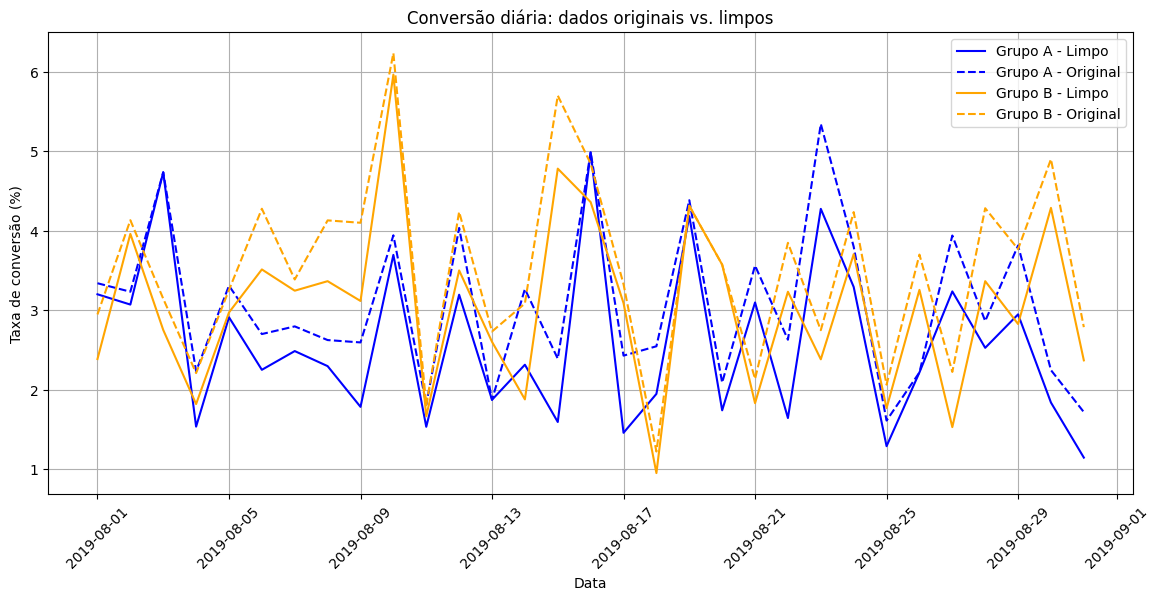

In [17]:
plt.figure(figsize=(14, 6))

# Grupo A - dados limpos
dados = conversion_clean[
    conversion_clean['group'] == 'A'
].sort_values('date')

plt.plot(
    dados['date'],
    dados['conversion'],
    label='Grupo A - Limpo',
    color='blue',
    linestyle='-'
)

# Grupo A - dados originais
dados = conversion_original[
    conversion_original['group'] == 'A'
].sort_values('date')

plt.plot(
    dados['date'],
    dados['conversion'],
    label='Grupo A - Original',
    color='blue',
    linestyle='--'
)

# Grupo B - dados limpos
dados = conversion_clean[
    conversion_clean['group'] == 'B'
].sort_values('date')

plt.plot(
    dados['date'],
    dados['conversion'],
    label='Grupo B - Limpo',
    color='orange',
    linestyle='-'
)

# Grupo B - dados originais
dados = conversion_original[
    conversion_original['group'] == 'B'
].sort_values('date')

plt.plot(
    dados['date'],
    dados['conversion'],
    label='Grupo B - Original',
    color='orange',
    linestyle='--'
)

plt.title('Conversão diária: dados originais vs. limpos')
plt.xlabel('Data')
plt.ylabel('Taxa de conversão (%)')

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.show()


In [27]:


 #Conferindo os dados de 17 e 18 de agosto
display(
    conversion_clean[
        (conversion_clean['group'] == 'B') &
        (conversion_clean['date'].between(
            '2019-08-17', '2019-08-18'
        ))
    ][['date', 'group', 'orders', 'visits', 'conversion']]
)

# Comparando a conversão diária dos grupos
comparison_daily = conversion_clean.pivot(
    index='date',
    columns='group',
    values='conversion'
).dropna(subset=['A', 'B'])

# Contando os dias em que cada grupo foi superior
days_B = (comparison_daily['B'] > comparison_daily['A']).sum()
days_A = (comparison_daily['A'] > comparison_daily['B']).sum()
days_equal = (comparison_daily['A'] == comparison_daily['B']).sum()

print(f'Dias com maior conversão em B: {days_B}')
print(f'Dias com maior conversão em A: {days_A}')
print(f'Dias com conversão igual: {days_equal}')

,date,group,orders,visits,conversion
47,2019-08-17,B,13,421,3.087886
48,2019-08-18,B,7,737,0.949796


Dias com maior conversão em B: 22
Dias com maior conversão em A: 9
Dias com conversão igual: 0



### Conclusão — Taxa de conversão diária por grupo

Ao analisar o gráfico de conversão diária, observei oscilações significativas nos grupos A e B durante todo o teste. O grupo B apresentou taxas superiores em diversos dias, mas as linhas se cruzaram frequentemente, sem uma separação duradoura. As diferenças entre os grupos foram pequenas em relação às oscilações diárias.

Um comportamento que chamou a atenção ocorreu em 18 de agosto, quando a conversão de B caiu de 3,09% para 0,95%. As visitas aumentaram de 421 para 737, enquanto os pedidos diminuíram de 13 para 7. Uma possível explicação é uma mudança no volume ou no perfil do tráfego, hipótese que precisaria de dados adicionais para ser confirmada.

Ao comparar os dados originais e limpos, observei que a remoção dos pedidos dos 58 visitantes reduziu a conversão calculada em ambos os grupos, com quedas muito próximas: **0,475 ponto percentual no grupo A e 0,486 no grupo B**.

Entretanto, a tabela de visitas continua contabilizando o tráfego desses visitantes, o que limita a precisão das taxas calculadas após a limpeza.

**Portanto, as oscilações e os cruzamentos frequentes não permitem identificar uma vantagem diária consistente apenas pelo gráfico. É necessário considerar a conversão acumulada, os testes estatísticos e as limitações dos dados para avaliar o desempenho dos grupos.**

### GRÁFICO DE DIFERENÇA RELATIVA NA CONVERSÃO CUMULATIVA DO GRUPO B PARA O GRUPO A 

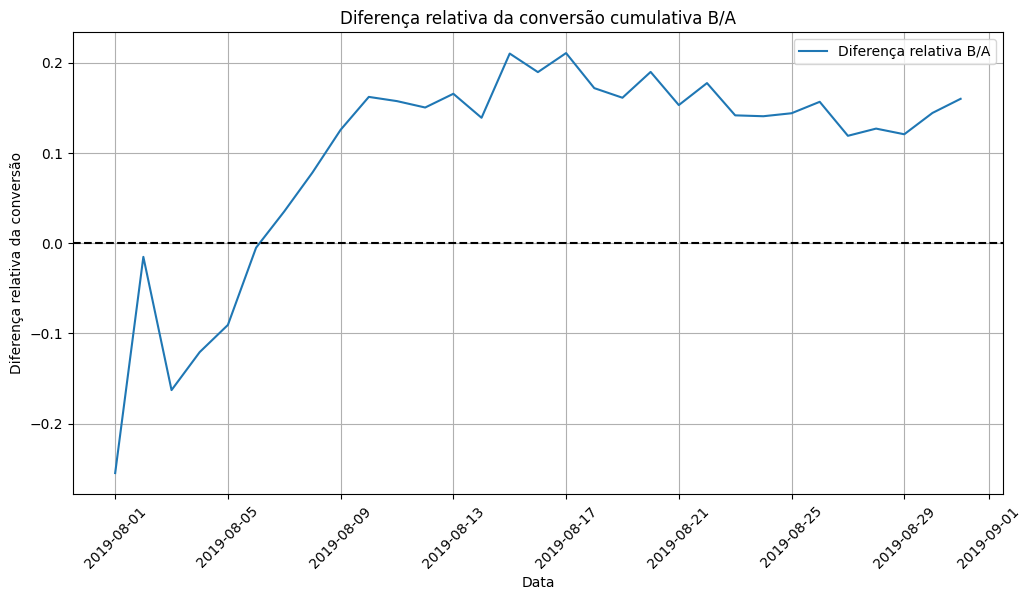

In [18]:

# Contando os pedidos por data e grupo
orders_daily = (
    orders_clean.groupby(['date', 'group'])
    .agg(orders=('transactionId', 'nunique'))
    .reset_index()
)

# Contando as visitas por data e grupo
visits_daily = (
    visits.groupby(['date', 'group'])
    .agg(visits=('visits', 'sum'))
    .reset_index()
)

# Juntando pedidos e visitas
daily_conversion = visits_daily.merge(
    orders_daily,
    on=['date', 'group'],
    how='left'
)

# Preenchendo dias sem pedidos
daily_conversion['orders'] = (
    daily_conversion['orders'].fillna(0)
)

# Organizando os dados por grupo e data
cumulative_conversion = daily_conversion.sort_values(
    by=['group', 'date']
).copy()

# Calculando os pedidos acumulados
cumulative_conversion['orders_cumulative'] = (
    cumulative_conversion.groupby('group')['orders'].cumsum()
)

# Calculando as visitas acumuladas
cumulative_conversion['visits_cumulative'] = (
    cumulative_conversion.groupby('group')['visits'].cumsum()
)

# Calculando a conversão cumulativa
cumulative_conversion['conversion_cumulative'] = (
    cumulative_conversion['orders_cumulative'] /
    cumulative_conversion['visits_cumulative']
)

# Separando os grupos A e B
conversionA = cumulative_conversion[
    cumulative_conversion['group'] == 'A'
].copy()

conversionB = cumulative_conversion[
    cumulative_conversion['group'] == 'B'
].copy()

# Juntando os grupos pela data
merged_conversion = conversionA.merge(
    conversionB,
    on='date',
    how='inner',
    suffixes=['A', 'B']
)

# Calculando a diferença relativa B/A
merged_conversion['relative_difference'] = (
    merged_conversion['conversion_cumulativeB'] /
    merged_conversion['conversion_cumulativeA']
) - 1

# Construindo o gráfico
plt.figure(figsize=(12, 6))

plt.plot(
    merged_conversion['date'],
    merged_conversion['relative_difference'],
    label='Diferença relativa B/A'
)

# 1inha de referência
plt.axhline(
    y=0,
    color='black',
    linestyle='--'
)

# Configurações
plt.title('Diferença relativa da conversão cumulativa B/A')
plt.xlabel('Data')
plt.ylabel('Diferença relativa da conversão')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.show()


### Conclusão — Diferença relativa da conversão cumulativa (B/A)

Ao analisar o gráfico, observei que o grupo B iniciou o teste com conversão inferior à do grupo A, mas ultrapassou seu desempenho na primeira semana de agosto, mantendo a vantagem até o final.

A diferença relativa atingiu aproximadamente **21%**, caiu para cerca de **12% entre os dias 27 e 29** e voltou a subir, encerrando o teste próxima de **16%**.

Essas oscilações podem estar relacionadas às variações na conversão diária ou a mudanças no perfil dos visitantes. Apesar de apresentar menor instabilidade na segunda metade do teste, a curva ainda não estava completamente estabilizada.

Além disso, a tabela de visitas ainda inclui os 58 visitantes removidos da base de pedidos, o que pode influenciar a comparação entre os grupos.

**Portanto, o grupo B apresenta indícios de melhor desempenho na conversão, mas essa vantagem precisa ser confirmada por testes estatísticos, considerando as limitações dos dados.**

### CALCULO DE PERCENTIS 95 E 99 PARA O NÚMERO DE PEDIDOS POR USUÁRIO 


In [19]:

# Contando os pedidos por usuário
ordersByUsers = (
    orders_clean.groupby('visitorId')['transactionId']
    .nunique()
)

# Calculando os percentis 95 e 99
print(np.percentile(ordersByUsers, [95, 99]))


[1. 2.]


### Conclusão percentis 95 e 99 para o número de pedidos por usuário.
Os percentis 95 e 99 foram de 1 e 2 pedidos por usuário, respectivamente, indicando que a maioria dos compradores realizou apenas um pedido.

Defini como limite para possíveis valores anômalos mais de 2 pedidos por usuário, utilizando o percentil 99 como referência. Embora esses pedidos possam ser legítimos, sua frequência é incomum em relação ao comportamento dos demais compradores.

### Gráfico de dispersão dos preços de pedidos


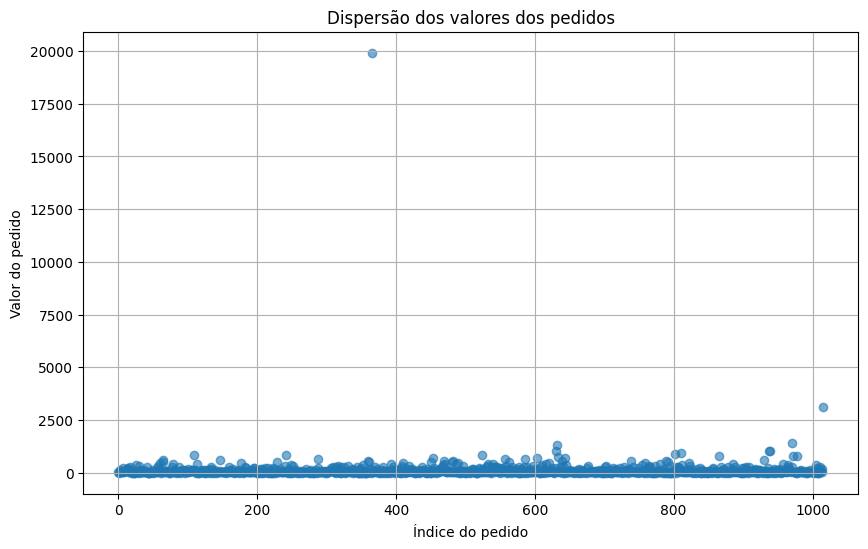

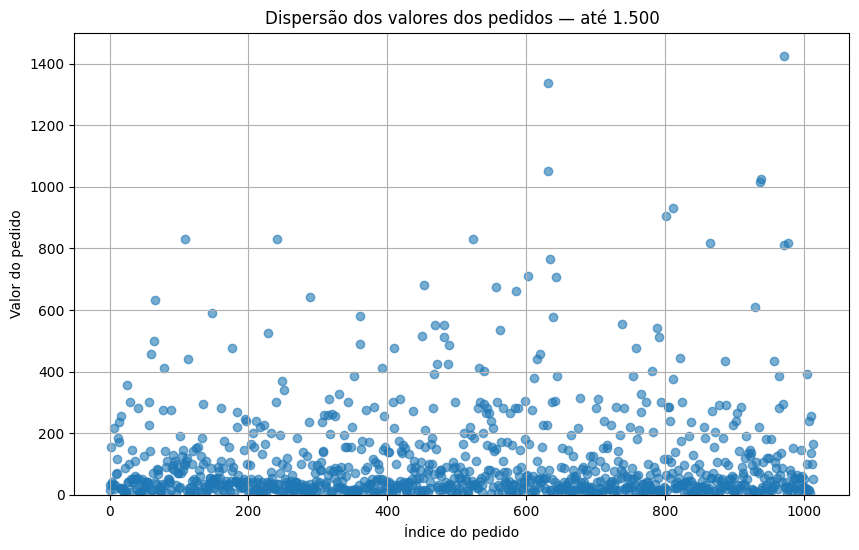

Percentis 95 e 99: [414.275 830.3  ]


In [14]:
# Criando os índices dos pedidos
x_values = pd.Series(range(0, len(orders_clean)))

# Gráfico 1 — Todos os valores dos pedidos
plt.figure(figsize=(10, 6))
plt.scatter(x_values, orders_clean['revenue'], alpha=0.6)

plt.title('Dispersão dos valores dos pedidos')
plt.xlabel('Índice do pedido')
plt.ylabel('Valor do pedido')
plt.grid(True)
plt.show()

# Gráfico 2 — Aproximação para observar a maioria dos pedidos
plt.figure(figsize=(10, 6))
plt.scatter(x_values, orders_clean['revenue'], alpha=0.6)

plt.title('Dispersão dos valores dos pedidos — até 1.500')
plt.xlabel('Índice do pedido')
plt.ylabel('Valor do pedido')
plt.ylim(0, 1500)
plt.grid(True)
plt.show()

# Percentis dos valores dos pedidos
print(
    'Percentis 95 e 99:',
    np.percentile(orders_clean['revenue'], [95, 99])
)

### Conclusão — Dispersão dos valores dos pedidos

Ao analisar o primeiro gráfico, observei a presença de um pedido excepcional de 19.920,40, muito acima dos demais valores, dificultando a visualização da distribuição dos pedidos.

No segundo gráfico, ao limitar o eixo vertical a 1.500, foi possível visualizar melhor a concentração dos pedidos de menor valor e identificar alguns pedidos mais elevados.

Os percentis calculados foram **414,28 para o percentil 95 e 830,30 para o percentil 99**, indicando que aproximadamente 95% dos pedidos apresentaram valores de até 414,28 e 99% de até 830,30.

Portanto, utilizei **830,30 como limite para identificar possíveis valores atípicos**, considerando os pedidos acima desse valor na análise estatística com dados filtrados.

### Calculo de percentis 95 e 99 dos preços dos pedidos 

In [21]:

# Calculando os percentis dos valores dos pedidos
print(np.percentile(orders_clean['revenue'], [95, 99]))




[414.275 830.3  ]



### Conclusão — Percentis dos valores dos pedidos

Ao calcular os percentis dos valores dos pedidos, identifiquei que o percentil 95 corresponde a **414,28** e o percentil 99 a **830,30**. Isso significa que aproximadamente 95% dos pedidos possuem valores de até 414,28 e 99% de até 830,30.

Ao analisar os pedidos acima desse limite, identifiquei valores excepcionais, como o pedido de **19.920,40 realizado em 19 de agosto** e o de **3.120,10 realizado em 15 de agosto**, ambos do grupo B.

Esses pedidos estão muito acima do percentil 99 e podem distorcer o valor médio dos pedidos, influenciando a comparação entre os grupos A e B.

**Portanto, defini 830,30 como limite para identificar possíveis valores atípicos**, que serão considerados na análise estatística com dados filtrados. Essa filtragem permitirá avaliar se as diferenças entre os grupos permanecem após a exclusão dos visitantes associados a pedidos extremos.

### Significância estátistica da diferença na conversão entre os grupos usando os dados brutos

- H₀ (hipótese nula): não existe diferença na distribuição do número de pedidos por visitante entre os grupos A e B.
- H₁ (hipótese alternativa): existe diferença na distribuição do número de pedidos por visitante entre os grupos A e B.

Utilizarei o teste de Mann-Whitney U, adotando um nível de significância de 5% (alpha = 0.05).

In [22]:
from scipy import stats as st

# Garantindo o formato de data
orders_clean['date'] = pd.to_datetime(orders_clean['date'])
visits['date'] = pd.to_datetime(visits['date'])

# Agrupando visitas por grupo
visits_by_group = visits.groupby('group')['visits'].sum()

# Contando pedidos por visitante no grupo A
ordersByUsersA = (
    orders_clean[orders_clean['group'] == 'A']
    .groupby('visitorId')['transactionId']
    .nunique()
)

# Contando pedidos por visitante no grupo B
ordersByUsersB = (
    orders_clean[orders_clean['group'] == 'B']
    .groupby('visitorId')['transactionId']
    .nunique()
)

# Adicionando zeros para os visitantes sem pedidos
sampleA = pd.concat([
    ordersByUsersA,
    pd.Series(
        0,
        index=range(
            int(visits_by_group['A']) - len(ordersByUsersA)
        )
    )
], ignore_index=True)

sampleB = pd.concat([
    ordersByUsersB,
    pd.Series(
        0,
        index=range(
            int(visits_by_group['B']) - len(ordersByUsersB)
        )
    )
], ignore_index=True)

# Nível de significância
alpha = 0.05

# Teste de Mann-Whitney
p_value = st.mannwhitneyu(
    sampleA,
    sampleB,
    alternative='two-sided'
).pvalue

# Diferença relativa na conversão
relative_difference = (
    (ordersByUsersB.sum() / visits_by_group['B']) /
    (ordersByUsersA.sum() / visits_by_group['A'])
) - 1

# Resultados
print(f'Valor-p: {p_value:.5f}')
print(f'Diferença relativa B/A: {relative_difference:.2%}')

if p_value < alpha:
    print('Rejeitamos a hipótese nula.')
else:
    print('Não rejeitamos a hipótese nula.')

Valor-p: 0.01102
Diferença relativa B/A: 15.98%
Rejeitamos a hipótese nula.



### Conclusão — Significância estatística da conversão com dados não filtrados por outliers

Nesta análise, utilizei os dados após a exclusão dos 58 visitantes que apareceram nos dois grupos do teste A/B, mas ainda sem remover os possíveis valores atípicos relacionados à quantidade e ao valor dos pedidos.

O teste U de Mann-Whitney apresentou um **valor-p de 0,01102**, inferior ao nível de significância de 5%. Portanto, rejeitamos a hipótese nula, encontrando evidências estatísticas de diferença entre os grupos.

A diferença relativa na conversão calculada foi de **15,98% a favor do grupo B**, resultado coerente com a tendência observada no gráfico de conversão cumulativa.

Uma possível explicação é que a versão B tenha facilitado a realização dos pedidos ou oferecido uma experiência de compra mais atrativa, incentivando mais visitantes a finalizar suas compras. Entretanto, essa hipótese não pode ser confirmada apenas pelos dados disponíveis.

Além disso, como a tabela de visitas contém valores agregados e não permite excluir as visitas dos 58 participantes removidos, os resultados devem ser interpretados com cautela.

**Portanto, o grupo B apresentou melhor conversão na análise realizada, mas ainda precisamos verificar se essa vantagem permanece após a remoção dos possíveis valores atípicos.**

### Significância estatistica da diferença no tamanho médio do pedido entre os grupos usando os dados brutos 

H₀ — Hipótese nula: não existe diferença na distribuição dos valores dos pedidos entre os grupos A e B.

H₁ — Hipótese alternativa: existe diferença na distribuição dos valores dos pedidos entre os grupos A e B.

Utilizarei novamente o teste de Mann-Whitney U, com nível de significância de 5%.

In [23]:
# Separando os valores dos pedidos do grupo A
sampleA = orders_clean[
    orders_clean['group'] == 'A'
]['revenue']

# Separando os valores dos pedidos do grupo B
sampleB = orders_clean[
    orders_clean['group'] == 'B'
]['revenue']

# Nível de significância
alpha = 0.05

# Teste de Mann-Whitney
p_value = st.mannwhitneyu(
    sampleA,
    sampleB,
    alternative='two-sided'
).pvalue

# Diferença relativa do valor médio dos pedidos
relative_difference = (
    sampleB.mean() / sampleA.mean()
) - 1

# Resultados
print(f'Valor-p: {p_value:.5f}')
print(f'Diferença relativa B/A: {relative_difference:.2%}')

# Decisão estatística
if p_value < alpha:
    print('Rejeitamos a hipótese nula.')
else:
    print('Não rejeitamos a hipótese nula.')

Valor-p: 0.86223
Diferença relativa B/A: 27.83%
Não rejeitamos a hipótese nula.


### Conclusão — Significância estatística do valor médio dos pedidos

Ao aplicar o teste de Mann-Whitney aos valores dos pedidos, obtive um valor-p de **0,86223**, superior ao nível de significância de 5%. Portanto, não rejeitei a hipótese nula, pois não foram encontradas evidências estatísticas suficientes de diferença entre as distribuições dos grupos A e B.

Entretanto, o valor médio dos pedidos do grupo B foi **27,83% superior** ao do grupo A.

Uma possível explicação para essa diferença é a influência de pedidos de valores elevados, como os identificados anteriormente no grupo B, que podem aumentar a média sem representar uma mudança generalizada no comportamento de compra.

**Portanto, apesar da média superior do grupo B, ainda não temos evidência estatística suficiente para afirmar uma diferença nas distribuições dos valores dos pedidos. Será importante comparar os resultados após o tratamento dos valores atípicos.**

### Significância estátistica da diferença na conversão entre os grupos usando os dados filtrados 
- H₀ (hipótese nula): não existe diferença na distribuição do número de pedidos por visitante entre os grupos A e B.

- H₁ (hipótese alternativa): existe diferença na distribuição do número de pedidos por visitante entre os grupos A e B.

- Nível de significância: alpha = 0.05.

Utilizarei novamente o teste de Mann-Whitney U para manter a comparação com o teste anterior.

In [24]:
# Contando pedidos por visitante
ordersByUsers = (
    orders_clean.groupby('visitorId')['transactionId']
    .nunique()
    .reset_index(name='orders')
)

# Visitantes com mais de 2 pedidos
usersWithManyOrders = ordersByUsers[
    ordersByUsers['orders'] > 2
]['visitorId']

# Visitantes com pedidos acima de 830.30
usersWithExpensiveOrders = orders_clean[
    orders_clean['revenue'] > 830.30
]['visitorId']

# 4. Unindo os visitantes anômalos
abnormalUsers = pd.concat([
    usersWithManyOrders,
    usersWithExpensiveOrders
]).drop_duplicates()

print('Quantidade de visitantes anômalos:', len(abnormalUsers))

# Contando pedidos por visitante no grupo A
ordersByUsersA = (
    orders_clean[orders_clean['group'] == 'A']
    .groupby('visitorId')['transactionId']
    .nunique()
)

# Contando pedidos por visitante no grupo B
ordersByUsersB = (
    orders_clean[orders_clean['group'] == 'B']
    .groupby('visitorId')['transactionId']
    .nunique()
)

# Total de visitas por grupo
visits_by_group = visits.groupby('group')['visits'].sum()

# Criando amostras com visitantes sem pedidos
sampleA = pd.concat([
    ordersByUsersA,
    pd.Series(
        0,
        index=range(
            int(visits_by_group['A']) - len(ordersByUsersA)
        )
    )
], ignore_index=True)

sampleB = pd.concat([
    ordersByUsersB,
    pd.Series(
        0,
        index=range(
            int(visits_by_group['B']) - len(ordersByUsersB)
        )
    )
], ignore_index=True)

# Excluindo os visitantes anômalos das amostras
# filtrando os pedidos identificados por usuário
ordersByUsersAFiltered = ordersByUsersA[
    ~ordersByUsersA.index.isin(abnormalUsers)
]

ordersByUsersBFiltered = ordersByUsersB[
    ~ordersByUsersB.index.isin(abnormalUsers)
]

# Mantendo os zeros referentes às visitas sem pedidos
sampleAFiltered = pd.concat([
    ordersByUsersAFiltered,
    pd.Series(
        0,
        index=range(
            int(visits_by_group['A']) - len(ordersByUsersA)
        )
    )
], ignore_index=True)

sampleBFiltered = pd.concat([
    ordersByUsersBFiltered,
    pd.Series(
        0,
        index=range(
            int(visits_by_group['B']) - len(ordersByUsersB)
        )
    )
], ignore_index=True)

# 10. Teste de Mann-Whitney
alpha = 0.05

p_value = st.mannwhitneyu(
    sampleAFiltered,
    sampleBFiltered,
    alternative='two-sided'
).pvalue

# 11. Diferença relativa B/A
relative_difference = (
    sampleBFiltered.mean() / sampleAFiltered.mean()
) - 1

# 12. Resultados
print(f'Valor-p: {p_value:.5f}')
print(f'Diferença relativa B/A: {relative_difference:.2%}')

if p_value < alpha:
    print('Rejeitamos H₀: há evidência de diferença estatística.')
else:
    print('Não rejeitamos H₀: evidência insuficiente de diferença estatística.')

Quantidade de visitantes anômalos: 16
Valor-p: 0.00702
Diferença relativa B/A: 18.92%
Rejeitamos H₀: há evidência de diferença estatística.


### Conclusão — Significância estatística da conversão com dados filtrados

Após remover os 16 visitantes identificados como possíveis valores atípicos, apliquei o teste U de Mann-Whitney e obtive um **valor-p de 0,00702**, inferior ao nível de significância de 5%. Portanto, rejeitei a hipótese nula.

A diferença relativa na conversão calculada foi de **18,92% a favor do grupo B**, superior aos 15,98% encontrados antes da filtragem.

Uma possível explicação para esse aumento é que os compradores frequentes removidos estivessem distribuídos de maneira desigual entre os grupos, influenciando mais a conversão do grupo A. Entretanto, seria necessário verificar a distribuição desses visitantes para confirmar essa hipótese.

O resultado sugere que a vantagem calculada do grupo B permanece após a remoção dos possíveis valores atípicos. Porém, a tabela de visitas contém dados agregados e não permite retirar as visitas desses participantes, o que limita a confiabilidade da análise.

**Portanto, a vantagem observada na conversão será considerada juntamente com o teste estatístico do valor dos pedidos para avaliar se o grupo B apresenta um desempenho suficientemente consistente para justificar sua implementação.**


## Significancia estátistica da diferença no tamanho médido do pedido entre os grupos usando os dados filtrados
H₀ (hipótese nula): não existe diferença na distribuição dos valores dos pedidos entre os grupos A e B.
H₁ (hipótese alternativa): existe diferença na distribuição dos valores dos pedidos entre os grupos A e B.
Nosso nível de significância será alpha = 0.05.
Utilizarei novamente o teste de Mann-Whitney U para manter a comparação com o teste anterior.

In [25]:
#  Removendo os 16 visitantes anômalos
orders_filtered = orders_clean[
    ~orders_clean['visitorId'].isin(abnormalUsers)
].copy()

# Selecionando os valores dos pedidos do grupo A
sampleA = orders_filtered[
    orders_filtered['group'] == 'A'
]['revenue']

#  Selecionando os valores dos pedidos do grupo B
sampleB = orders_filtered[
    orders_filtered['group'] == 'B'
]['revenue']

#  Aplicando o teste de Mann-Whitney
alpha = 0.05

p_value = st.mannwhitneyu(
    sampleA,
    sampleB,
    alternative='two-sided'
).pvalue

# Calculando a diferença relativa das médias
relative_difference = (
    sampleB.mean() / sampleA.mean()
) - 1

# Exibindo os resultados
print(f'Valor-p: {p_value:.5f}')
print(f'Diferença relativa B/A: {relative_difference:.2%}')

#  Decisão estatística
if p_value < alpha:
    print('Rejeitamos H₀: há evidência de diferença estatística.')
else:
    print('Não rejeitamos H₀: evidência insuficiente de diferença estatística.')

Valor-p: 0.82203
Diferença relativa B/A: -3.19%
Não rejeitamos H₀: evidência insuficiente de diferença estatística.


### Conclusão — Significância estatística do tamanho médio dos pedidos com dados filtrados

Após remover os 16 visitantes identificados como possíveis valores atípicos, obtive um valor-p de **0,82203**, superior ao nível de significância de 5%. Portanto, não rejeitei a hipótese nula.

A diferença relativa do valor médio dos pedidos passou de **+27,83% nos dados não filtrados para -3,19% nos dados filtrados**, indicando uma inversão na vantagem observada entre os grupos.

Essa mudança sugere que os pedidos de valores elevados influenciaram significativamente a média do grupo B. Entretanto, os testes de Mann-Whitney não apresentaram evidências estatísticas suficientes de diferença entre as distribuições dos valores dos pedidos em nenhum dos cenários.

**Portanto, não há evidências suficientes para afirmar que um dos grupos apresenta valores de pedidos sistematicamente superiores. A comparação das médias mostrou-se sensível à presença dos valores atípicos.**

### Conclusão final — Teste A/B

Após analisar os gráficos e os resultados estatísticos, **recomendo interromper o teste A/B e considerar o grupo B como vencedor em conversão**.

O grupo B apresentou uma vantagem relativa de **15,98% na conversão antes da remoção dos outliers (p = 0,01102)** e **18,92% após a filtragem (p = 0,00702)**. Em ambos os casos, os valores-p ficaram abaixo de 0,05. Além disso, a conversão acumulada do grupo B terminou aproximadamente 16% acima da do grupo A.

Em relação ao valor médio dos pedidos, não encontramos evidências estatísticas suficientes de diferença entre os grupos (p = 0,86223 e p = 0,82203). A vantagem inicial de 27,83% do grupo B passou para -3,19% após a remoção dos valores atípicos, indicando que os pedidos elevados influenciaram a média.

Portanto, a principal vantagem do grupo B está na **maior quantidade de pedidos por visita calculada**, e não no aumento do valor médio dos pedidos. Esse resultado pode contribuir para o objetivo do negócio de aumentar a receita.

Entretanto, existe uma limitação: a tabela de visitas contém dados agregados e ainda inclui o tráfego dos 58 visitantes removidos da análise de pedidos, o que reduz a confiabilidade das estimativas de conversão.

**Diante dos resultados, recomendo encerrar o teste e selecionar o grupo B como líder em conversão, ressaltando que a implementação deve considerar essa limitação dos dados.**